# Predicting Credit Card Fraud

## Exploratory Data Analysis

### Dataset Overview and Structure

In [1]:
# Import libraries

import time

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

print("Libraries imported successfully...Bliss")

Libraries imported successfully...Bliss


In [2]:
sample_path = "/kaggle/input/competitions/playground-series-s6e11/sample_submission.csv"
test_path = "/kaggle/input/competitions/playground-series-s6e11/test.csv"
train_path = "/kaggle/input/competitions/playground-series-s6e11/train.csv"

print("Path assign")

Path assign


In [3]:
start = time.time()

sample_df = pd.read_csv(sample_path)
test_df = pd.read_csv(test_path)
train_df = pd.read_csv(train_path)

data_load_time = time.time() - start
print("Data loaded successfully")
print(f"Time take: {data_load_time}")

Data loaded successfully
Time take: 4.6074700355529785


In [4]:
df_dict = {
    "Sample_df": sample_df,
    "test_df": test_df,
    "train_df": train_df
}
print("Dict created")

Dict created


In [5]:
for key, value in df_dict.items():
    print(f"Shape of {key}")
    print(f"Rows: {value.shape[0]} | Columns: {value.shape[1]}")
    print("-"*30)

Shape of Sample_df
Rows: 299984 | Columns: 2
------------------------------
Shape of test_df
Rows: 299984 | Columns: 25
------------------------------
Shape of train_df
Rows: 699960 | Columns: 26
------------------------------


In [6]:
# Inspect data

print("Sample DataFrame\n")
display(sample_df.head())

print("\nTest DataFrame\n")
display(test_df.head())

print("\nTrain DataFrame\n")
display(train_df.head())
display(train_df.tail())

Sample DataFrame



,id,is_fraud
0,699960,0.0167
1,699961,0.0167
2,699962,0.0167
3,699963,0.0167
4,699964,0.0167



Test DataFrame



,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,...,Visa,OTP,Online,iPhone,False,False,False,False,False,False
1,699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,...,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
2,699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,...,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False
3,699963,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,...,Mastercard,PIN,Contactless,Mac,False,False,False,False,False,False
4,699964,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,...,Mastercard,PIN,In-App,Android Phone,False,False,False,False,False,False



Train DataFrame



,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
699955,699955,715.39,4.10,3,3.24,45,31,1598.50,0,20.8,...,3D Secure,POS,Windows PC,False,False,False,False,False,False,0.0
699956,699956,32.28,0.04,6,8.56,44,81,2149.48,1,65.0,...,No Authentication,Online,iPhone,False,False,False,False,False,False,0.0
699957,699957,22.95,4.99,4,4.23,37,69,959.88,0,19.3,...,Biometric,Online,Android Phone,False,False,True,False,False,False,0.0
699958,699958,14.19,1.86,4,28.08,40,72,1362.85,0,31.0,...,PIN,ATM,Windows PC,False,False,True,False,False,False,0.0
699959,699959,36.16,3.51,3,1.53,48,21,2645.98,0,8.9,...,Biometric,Online,Android Phone,False,False,False,False,False,False,0.0


In [7]:
# Statistical summary
display('Numerical Columns', train_df.describe().T)
display('Categorical Columns', train_df.describe(include="object").T)

'Numerical Columns'

,count,mean,std,min,25%,50%,75%,max
id,699960.0,349979.500000,202061.191548,0.00,174989.75,349979.50,524969.25,699959.00
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90


'Categorical Columns'

,count,unique,top,freq
merchant_category,699960,12,Online Retail,155097
card_type,699960,5,Visa,345001
auth_method,699960,5,3D Secure,210036
channel,699960,5,Online,273939
device_type,699960,8,Android Phone,237454


In [8]:
# Data quality checks

print(f"Missing value:\n {train_df.isnull().sum().sum()}")
print(f"Duplicate rows:\n {train_df.duplicated().sum()}")
print(f"Duplicate ID's:\n {train_df["id"].duplicated().sum()}")
print(f"Data types:\n {train_df.dtypes}")

Missing value:
 0
Duplicate rows:
 0
Duplicate ID's:
 0
Data types:
 id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                object
card_type                        object
auth_method                      object
channel                          object
device_type                      object
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shi

### Target Distribution

In [9]:
print(train_df["is_fraud"].value_counts())
print("-"*30)
print(round(train_df["is_fraud"].value_counts(normalize=True)*100, 2))

is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64
------------------------------
is_fraud
0.0    98.33
1.0     1.67
Name: proportion, dtype: float64


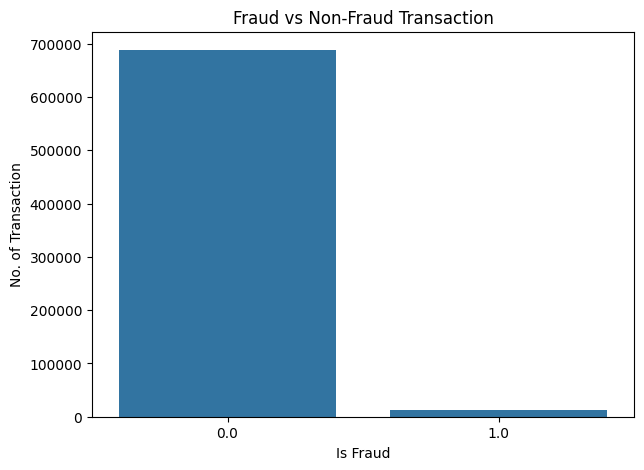

In [10]:
# visualize
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="is_fraud"
)

plt.title("Fraud vs Non-Fraud Transaction")
plt.xlabel("Is Fraud")
plt.ylabel("No. of Transaction")
plt.show()

In [11]:
numerical_cols = train_df.select_dtypes(include=["int64", "float64"]).columns.tolist()

numerical_cols.remove("id")
numerical_cols.remove("is_fraud")
print(numerical_cols)

['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']


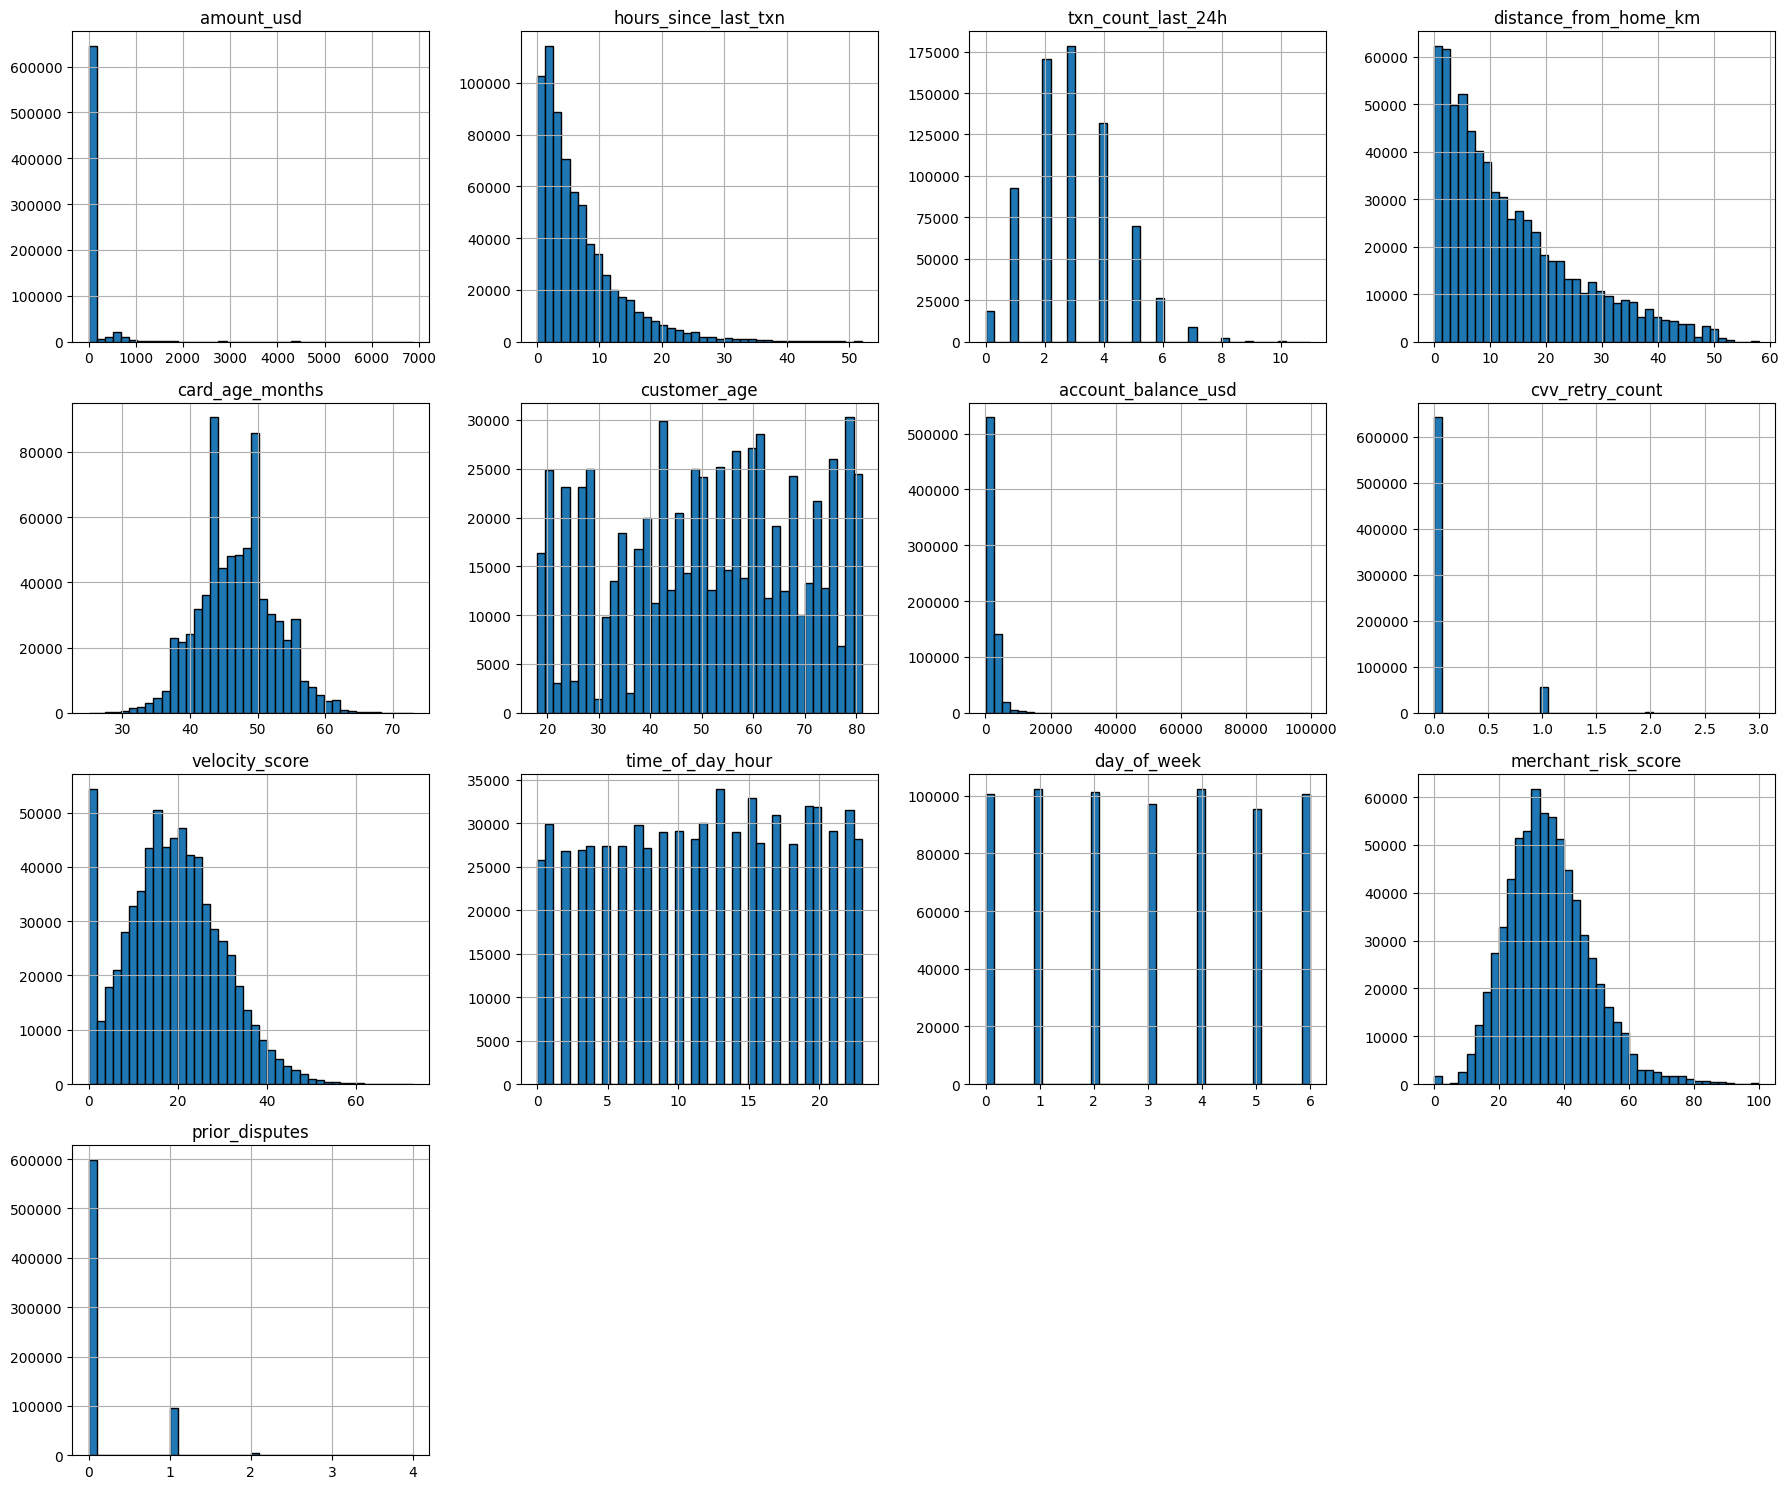

In [12]:
# visualize

train_df[numerical_cols].hist(
    figsize=(18, 15),
    bins=40,
    edgecolor="black"
)

plt.title("Numerical Feature Distribution")
plt.tight_layout()
plt.show()

In [13]:
categorical_cols = train_df.select_dtypes(include=["bool", "object", "category"]).columns.tolist()
print(categorical_cols)

['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


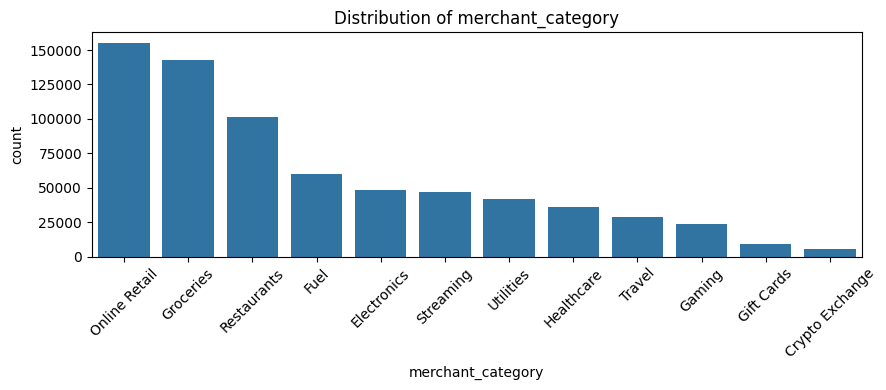

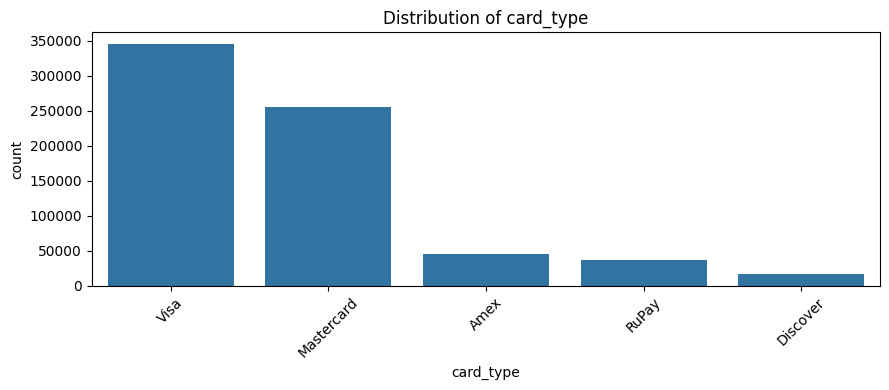

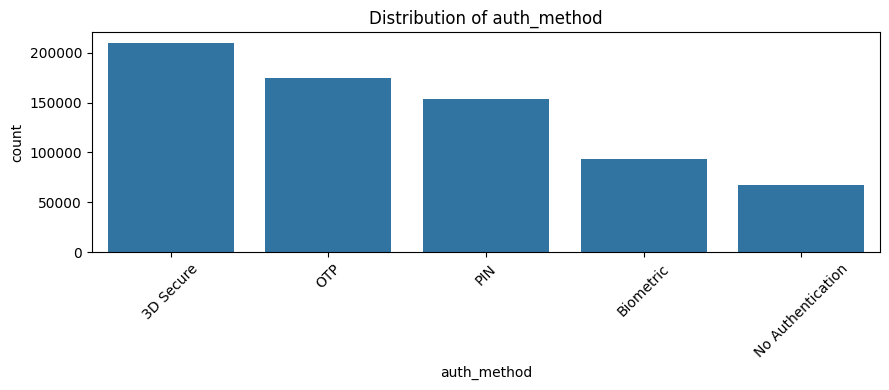

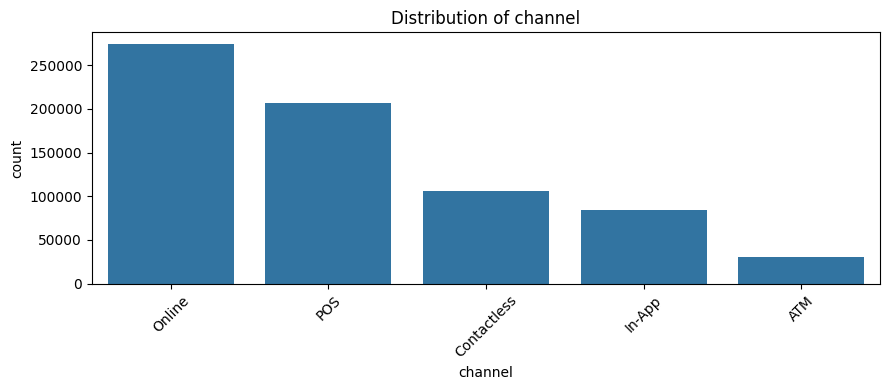

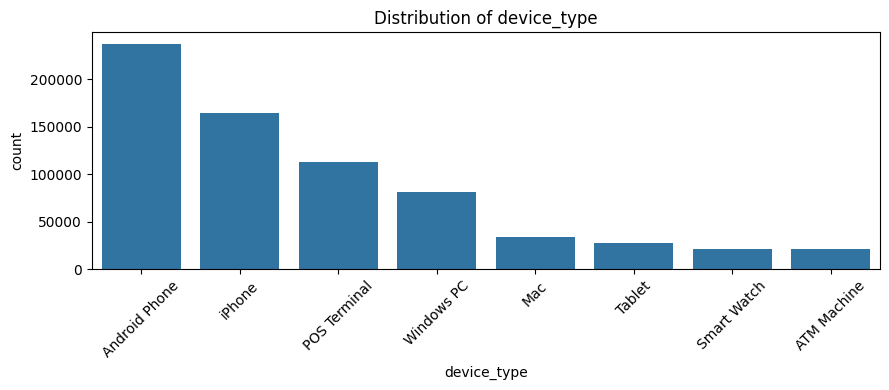

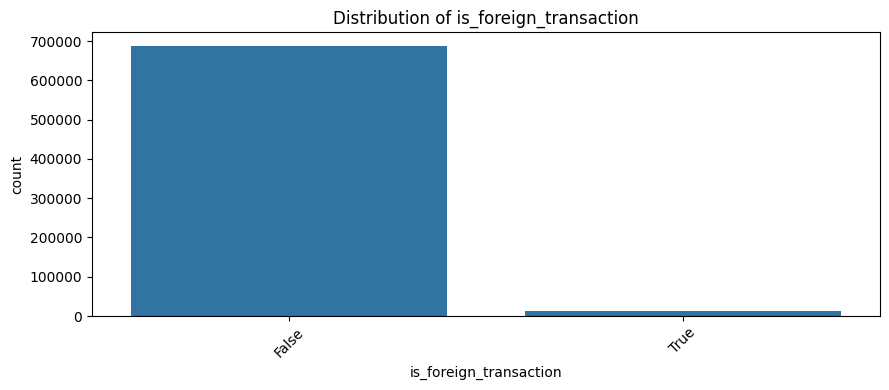

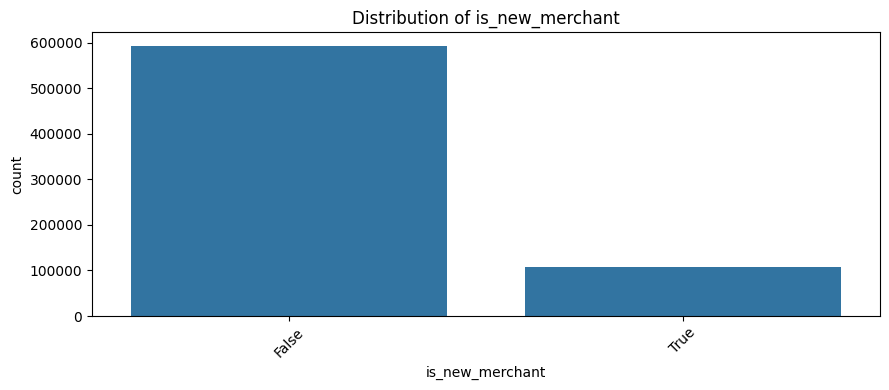

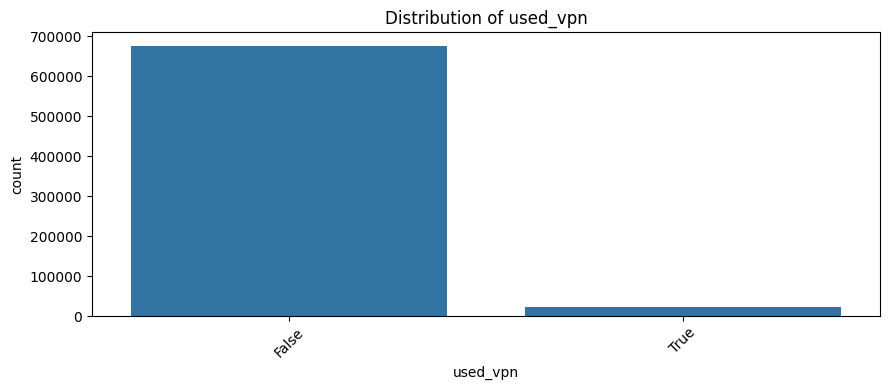

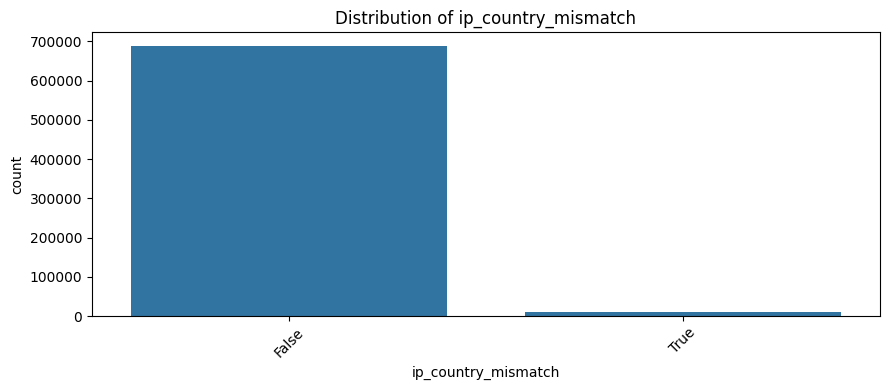

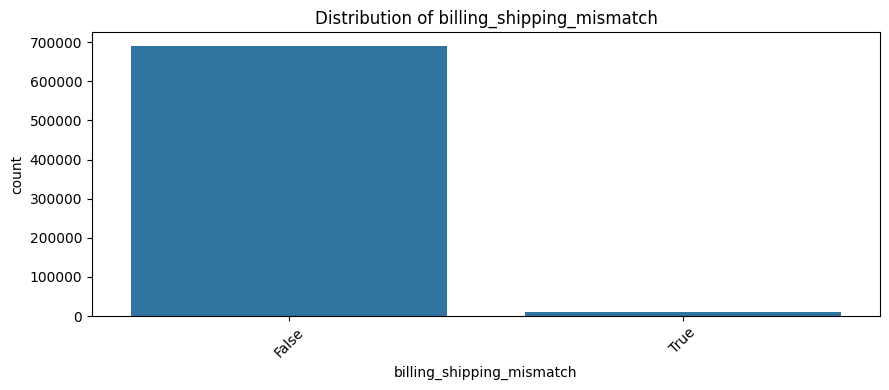

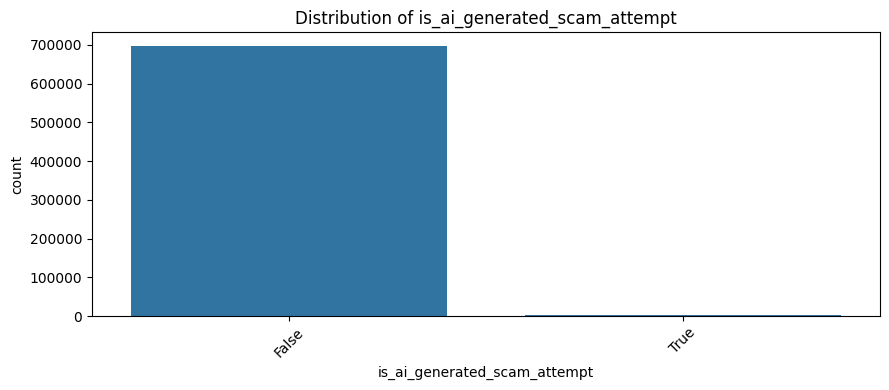

In [14]:
# visualize

for col in categorical_cols:
    plt.figure(figsize=(9, 4))

    sns.countplot(
        data=train_df,
        x=col,
        order=train_df[col].value_counts().index
    )
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Bivariate Analysis

In [15]:
count = 1
for key, value in df_dict.items():
    if key == "train_df":
        print(f"Categorical columns:\n")
        for col in value.columns:
            if len(train_df[col].unique()) < 15:
                print(f"{count}. {col}: {train_df[col].unique()}")
                print("-"*70)
                count = count + 1
print(f"\nThere are {count-1} columns in train_df dataset")

Categorical columns:

1. txn_count_last_24h: [ 1  3  4  6  5  2  0  7  8  9 10 11]
----------------------------------------------------------------------
2. cvv_retry_count: [0 1 2 3]
----------------------------------------------------------------------
3. day_of_week: [3 5 0 4 2 1 6]
----------------------------------------------------------------------
4. prior_disputes: [0 1 3 2 4]
----------------------------------------------------------------------
5. merchant_category: ['Groceries' 'Online Retail' 'Utilities' 'Electronics' 'Healthcare'
 'Restaurants' 'Fuel' 'Streaming' 'Crypto Exchange' 'Gaming' 'Travel'
 'Gift Cards']
----------------------------------------------------------------------
6. card_type: ['Mastercard' 'Visa' 'Amex' 'RuPay' 'Discover']
----------------------------------------------------------------------
7. auth_method: ['OTP' 'PIN' '3D Secure' 'Biometric' 'No Authentication']
----------------------------------------------------------------------
8. channel: ['PO

In [16]:
categorical_cols = train_df.select_dtypes(include=["object", "bool"]).columns.tolist()
print("cat_cols lenght", categorical_cols)
print("-"*70)
numerical_cols = train_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
print("num_cols lenght", numerical_cols)

cat_cols lenght ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']
----------------------------------------------------------------------
num_cols lenght ['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'is_fraud']


In [17]:
train_df.isnull().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64